# 01 — Exploration du jeu de données (rôle A)

Jeu « familles de malwares » préparé par `python -m malware_family.prepare` à partir
d'EMBER2024 : uniquement des features statiques déjà extraites, aucun binaire.

1. Les familles sont-elles équilibrées, dans le train et dans le test ?
2. Comment les échantillons se répartissent-ils dans le temps ?
3. Les étiquettes de famille sont-elles sûres (`family_confidence`) ?
4. Combien de features sont constantes, et dans quels groupes ? → à transmettre à B
5. Combien de malwares du test appartiennent à d'autres familles ?

Les figures sont enregistrées dans `results/figures/` (préfixe `A_`).
Avant de commiter : *Kernel → Restart Kernel and Clear Outputs*.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.dates as mdates
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from malware_family.dataset import load_dataset
from malware_family.ember_features import feature_groups
from malware_family.figures import CM, family_colors, new_figure, save_figure, use_style

# Jeu préparé par « python -m malware_family.prepare » : à adapter, ou variable d'environnement
# EMBER_DATASET (ex. C:\ember2024\processed\Win32_top10). Les mêmes données pour A, B et C.
DATASET = Path(os.environ.get("EMBER_DATASET", ROOT / "data" / "processed" / "ember2024_Win32_top10")).expanduser()

data = load_dataset(DATASET)
families = data.families
colors = family_colors(families)
use_style()
print(f"{DATASET.name} : {len(data.y_train)} échantillons en train, {len(data.y_test)} en test, "
      f"{len(families)} familles, {len(data.feature_names)} features")

Win32_top10 : 100000 échantillons en train, 49658 en test, 10 familles, 2568 features


## 1. Effectifs par famille

`prepare` plafonne chaque famille (`--max-per-family`, 10 000 par défaut) : on compare
les effectifs **retenus** aux effectifs **disponibles** dans EMBER2024 (`family_counts.csv`).

In [2]:
all_counts = pd.read_csv(DATASET / "family_counts.csv", index_col="family", keep_default_na=False)
counts = pd.DataFrame({
    "train": np.bincount(data.y_train, minlength=len(families)),
    "test": np.bincount(data.y_test, minlength=len(families)),
    "train disponible": all_counts.loc[families, "train"].to_numpy(),
    "test disponible": all_counts.loc[families, "test"].to_numpy(),
}, index=pd.Index(families, name="famille"))
for split in ("train", "test"):
    counts[f"part {split} (%)"] = (100 * counts[split] / max(counts[split].sum(), 1)).round(1)
display(counts)


def imbalance(column):
    """Rapport entre la famille la plus fréquente et la plus rare (parmi celles présentes)."""
    present = column[column > 0]
    return present.max() / present.min() if len(present) else float("nan")


for column in ("train", "test", "train disponible", "test disponible"):
    print(f"Déséquilibre {column:<17} : x{imbalance(counts[column]):.1f}")
absent = list(counts.index[counts.test == 0])
if absent:
    print("Familles absentes du test :", ", ".join(absent))

,train,test,train disponible,test disponible,part train (%),part test (%)
famille,,,,,,
berbew,10000,10000,256810,92086,10.0,20.1
cosmu,10000,9562,60786,9562,10.0,19.3
wacatac,10000,10000,45118,12238,10.0,20.1
sfone,10000,132,44216,132,10.0,0.3
upatre,10000,6430,43954,6430,10.0,12.9
grandoreiro,10000,226,40728,226,10.0,0.5
glupteba,10000,3412,39814,3412,10.0,6.9
expiro,10000,7966,35434,7966,10.0,16.0
sinowal,10000,18,34560,18,10.0,0.0


Déséquilibre train             : x1.0
Déséquilibre test              : x555.6
Déséquilibre train disponible  : x7.5
Déséquilibre test disponible   : x5115.9


Figure : results\figures\A_effectifs_familles.png


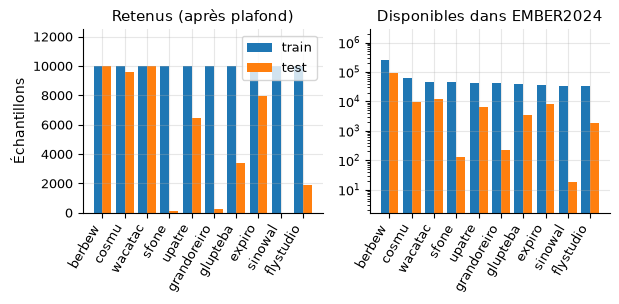

In [3]:
fig, axes = new_figure(height=8 * CM, ncols=2)
x = np.arange(len(families))
panels = [("Retenus (après plafond)", ["train", "test"]),
          ("Disponibles dans EMBER2024", ["train disponible", "test disponible"])]
for ax, (title, columns) in zip(axes, panels):
    for k, column in enumerate(columns):
        ax.bar(x + (k - 0.5) * 0.4, counts[column], width=0.4, color=f"C{k}", label=column.split()[0])
    ax.set_xticks(x, families, rotation=60, ha="right")
    ax.set_title(title)
    ax.margins(y=0.25)  # place pour la légende
axes[0].set_ylabel("Échantillons")
axes[1].set_yscale("log")
axes[0].legend()
fig.tight_layout()
print("Figure :", save_figure(fig, "A_effectifs_familles").relative_to(ROOT))

## 2. Échantillons par semaine

Le découpage d'EMBER2024 est temporel : le train couvre les 52 premières semaines, le test
les 12 dernières. `first_seen` (`meta_*.csv`) est la date de première soumission à VirusTotal.

In [4]:
meta = pd.concat([data.meta_train.assign(split="train"), data.meta_test.assign(split="test")],
                 ignore_index=True)
meta["first_seen"] = pd.to_datetime(meta.first_seen, errors="coerce")
print(f"Dates manquantes : {meta.first_seen.isna().sum()}")
meta["semaine"] = meta.first_seen.dt.to_period("W").dt.start_time
weekly = (meta.pivot_table(index="semaine", columns="family", values="sha256", aggfunc="count", fill_value=0)
          .reindex(columns=families, fill_value=0))
test_start = meta.loc[meta.split == "test", "first_seen"].min()
weeks = meta.groupby("split").semaine.nunique()
print(f"Semaines : {weeks.get('train', 0)} en train, {weeks.get('test', 0)} en test"
      + (f" ; début du test : {test_start:%d/%m/%Y}" if pd.notna(test_start) else ""))
print("Échantillons par semaine :")
display(meta.groupby(["split", "semaine"]).size().groupby("split").describe().round(0))

Dates manquantes : 0
Semaines : 53 en train, 13 en test ; début du test : 22/09/2024
Échantillons par semaine :


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,13.0,3820.0,879.0,1084.0,3795.0,4001.0,4171.0,4668.0
train,53.0,1887.0,678.0,161.0,1497.0,1815.0,2220.0,4051.0


Figure : results\figures\A_echantillons_par_semaine.png


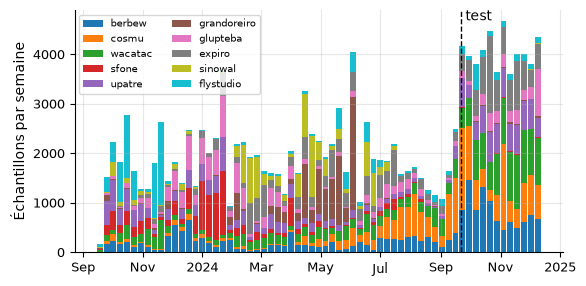

In [5]:
fig, ax = new_figure(height=8 * CM)
bottom = np.zeros(len(weekly))
for family in families:
    ax.bar(weekly.index, weekly[family], bottom=bottom, width=pd.Timedelta(days=6),
           color=colors[family], label=family)
    bottom += weekly[family].to_numpy()
if pd.notna(test_start):
    ax.axvline(test_start, color="black", linestyle="--", linewidth=1)
    ax.annotate(" test", (test_start, 1), xycoords=("data", "axes fraction"), va="top")
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.set_ylabel("Échantillons par semaine")
ax.legend(ncol=2, fontsize=7, loc="upper left")
print("Figure :", save_figure(fig, "A_echantillons_par_semaine").relative_to(ROOT))

## 3. Confiance des étiquettes (`family_confidence`)

ClarAVy donne à chaque étiquette de famille un score de confiance entre 0 et 1. La variante
`--min-confidence 0.5` (expérience de B) ne garde que les étiquettes les plus sûres.

In [6]:
confidence = meta.groupby(["family", "split"]).family_confidence
table = (pd.concat({"médiane": confidence.median(),
                    "% >= 0,5": confidence.apply(lambda c: 100 * (c >= 0.5).mean())}, axis=1)
         .unstack("split").reindex(families).round(2))
display(table)
for split in ("train", "test"):
    part = meta[meta.split == split]
    print(f"{split} : {(part.family_confidence >= 0.5).sum()} / {len(part)} échantillons retenus "
          "auraient family_confidence >= 0,5")

médiane       % >= 0,5       
split          test train     test  train
family                                   
berbew         0.86  0.86    86.87  82.86
cosmu          0.84  0.85    97.11  97.72
wacatac        0.16  0.13     1.47   0.68
sfone          0.26  0.86    42.42  82.75
upatre         0.55  0.66    53.84  66.52
grandoreiro    0.68  0.30    79.65   4.89
glupteba       0.60  0.27    60.43  18.62
expiro         0.86  0.86    92.72  95.98
sinowal        0.27  0.19    44.44   4.60
flystudio      0.35  0.33    24.90  28.89

train : 48351 / 100000 échantillons retenus auraient family_confidence >= 0,5
test : 31750 / 49658 échantillons retenus auraient family_confidence >= 0,5


Figure : results\figures\A_confiance_etiquettes.png


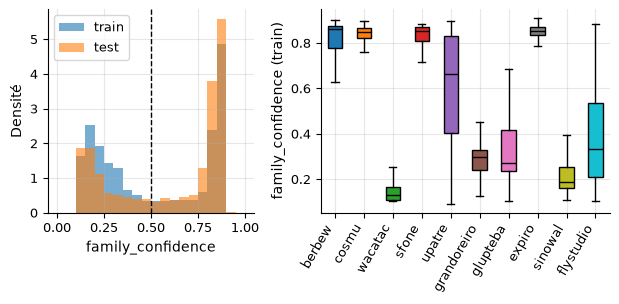

In [7]:
fig, (ax1, ax2) = new_figure(height=8 * CM, ncols=2, width_ratios=[1, 1.4])
bins = np.linspace(0, 1, 21)
for k, split in enumerate(("train", "test")):
    ax1.hist(meta.loc[meta.split == split, "family_confidence"].dropna(), bins=bins, density=True,
             alpha=0.6, color=f"C{k}", label=split)
ax1.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax1.set_xlabel("family_confidence")
ax1.set_ylabel("Densité")
ax1.legend()
train_meta = meta[meta.split == "train"]
boxes = ax2.boxplot([train_meta.loc[train_meta.family == f, "family_confidence"].dropna() for f in families],
                    patch_artist=True, showfliers=False, medianprops={"color": "black"})
for patch, family in zip(boxes["boxes"], families):
    patch.set_facecolor(colors[family])
ax2.set_xticks(range(1, len(families) + 1), families, rotation=60, ha="right")
ax2.set_ylabel("family_confidence (train)")
fig.tight_layout()
print("Figure :", save_figure(fig, "A_confiance_etiquettes").relative_to(ROOT))

## 4. Features constantes

Une colonne constante sur tout le train n'apporte rien au modèle. `VarianceThreshold(threshold=0)`
de scikit-learn supprime exactement les colonnes dont le minimum est égal au maximum : on fait le
même calcul **par blocs**, sans charger X en mémoire (≈ 1 Go pour 10 familles).

On compte aussi les colonnes **presque toujours nulles** (non nulles dans moins de 0,1 % des
échantillons du train), fréquentes parmi les cases hachées.

In [8]:
def column_stats(X, block=10_000):
    """Minimum, maximum et nombre de valeurs non nulles de chaque colonne, lus par blocs."""
    lo, hi = np.full(X.shape[1], np.inf), np.full(X.shape[1], -np.inf)
    nonzero = np.zeros(X.shape[1], dtype=np.int64)
    for start in range(0, len(X), block):
        chunk = np.asarray(X[start:start + block])
        lo, hi = np.minimum(lo, chunk.min(axis=0)), np.maximum(hi, chunk.max(axis=0))
        nonzero += np.count_nonzero(chunk, axis=0)
    return lo, hi, nonzero


names = np.array(data.feature_names)
lo, hi, nonzero = column_stats(data.X_train)
constant = lo == hi
rare = ~constant & (nonzero < 0.001 * len(data.X_train))
lo_test, hi_test, _ = column_stats(data.X_test)
varies_in_test = constant & ((lo_test < lo) | (hi_test > hi))

by_group = pd.DataFrame([
    {"groupe": group, "colonnes": part.stop - part.start, "constantes (train)": constant[part].sum(),
     "presque toujours nulles": rare[part].sum(),
     "constantes en train, variables en test": varies_in_test[part].sum()}
    for group, part in feature_groups().items()]).set_index("groupe")
by_group.loc["total"] = by_group.sum()
display(by_group)

,colonnes,constantes (train),presque toujours nulles,"constantes en train, variables en test"
groupe,,,,
general,7,2,0,0
histogram,256,0,0,0
byteentropy,256,0,0,0
strings,177,3,5,1
header,74,1,6,0
section,224,3,0,0
imports,1282,1,155,1
exports,129,0,0,0
datadirectories,34,3,6,0


In [9]:
out = ROOT / "results" / f"features_constantes_{DATASET.name}.txt"
out.parent.mkdir(exist_ok=True)
out.write_text("".join(f"{name}\n" for name in names[constant]), encoding="utf-8")
print(f"{constant.sum()} features constantes en train (liste pour B : {out.relative_to(ROOT)})")
display(pd.DataFrame({"feature": names[constant], "valeur": lo[constant]}).head(30))

46 features constantes en train (liste pour B : results\features_constantes_Win32_top10.txt)


,feature,valeur
0,general_start_byte0,77.0
1,general_start_byte1,90.0
2,strings_pattern_Invoke-Expression,0.0
3,strings_pattern_Start-process,0.0
4,strings_pattern_base64string,0.0
5,header_characteristic_16BIT_MACHINE,0.0
6,section_entropy_min,0.0
7,section_size_ratio_min,0.0
8,section_vsize_ratio_min,0.0
9,imports_library_hash033,0.0


Pour B, la même sélection dans un pipeline scikit-learn :

```python
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import make_pipeline

model = make_pipeline(VarianceThreshold(0.0), RandomForestClassifier(n_estimators=100, random_state=0))
```

## 5. Malwares du test d'autres familles

Le classifieur ne connaît que les familles retenues : `prepare` écarte les malwares du test
des autres familles. En conditions réelles, il recevrait aussi ces fichiers (« monde ouvert »).

In [10]:
info = data.info
labels = pd.DataFrame(info["ember_label_counts"]).T
labels["malwares avec famille"] = pd.Series(info["malware_with_family"])
labels["retenus"] = pd.Series(info["n_samples"])
display(labels)

other = info["test_malware_other_families"]
with_family = info["malware_with_family"]["test"]
others = all_counts[~all_counts.selected]
print(f"Test : {with_family} malwares avec famille, dont {other} ({100 * other / max(with_family, 1):.1f} %) "
      f"de {(others.test > 0).sum()} autres familles, écartés.")
only_test = all_counts[(all_counts.train == 0) & (all_counts.test > 0)]
print(f"Familles absentes du train : {len(only_test)} ({only_test.test.sum()} malwares du test)")
print("Familles écartées les plus fréquentes dans le test :")
display(others.sort_values("test", ascending=False).head(10))

,benign,malicious,malwares avec famille,retenus
train,1560000,1560000,1371318,100000
test,360000,360000,319822,49658


Test : 319822 malwares avec famille, dont 185840 (58.1 %) de 3012 autres familles, écartés.
Familles absentes du train : 390 (1934 malwares du test)
Familles écartées les plus fréquentes dans le test :


,train,test,selected
family,,,
virlock,7828,5660,False
floxif,13686,5508,False
lummastealer,2312,4858,False
virut,14972,4264,False
aenjaris,6708,4226,False
snackarcin,3710,4084,False
swisyn,8380,3294,False
stealc,3178,3292,False
amadey,3762,2958,False


## 6. Synthèse à transmettre à B

In [11]:
print(f"Constats de l'exploration ({DATASET.name}) :")
print(f"- déséquilibre : train x{imbalance(counts.train):.1f} "
      f"(x{imbalance(counts['train disponible']):.1f} avant plafond), test x{imbalance(counts.test):.1f}")
print(f"- {constant.sum()} features constantes en train, à retirer (VarianceThreshold) : "
      f"results/{out.name}")
print(f"- {rare.sum()} features presque toujours nulles (< 0,1 % des échantillons du train)")
print(f"- {100 * (meta.family_confidence >= 0.5).mean():.0f} % des étiquettes ont family_confidence >= 0,5")
print(f"- {other} malwares du test d'autres familles, écartés")

Constats de l'exploration (Win32_top10) :
- déséquilibre : train x1.0 (x7.5 avant plafond), test x555.6
- 46 features constantes en train, à retirer (VarianceThreshold) : results/features_constantes_Win32_top10.txt
- 204 features presque toujours nulles (< 0,1 % des échantillons du train)
- 54 % des étiquettes ont family_confidence >= 0,5
- 185840 malwares du test d'autres familles, écartés


**À compléter après exécution sur les vraies données :**

- Déséquilibre : …
- Évolution dans le temps : …
- Confiance des étiquettes : …
- Features constantes : …
- Conséquences pour B (métriques adaptées au déséquilibre, `class_weight`, `VarianceThreshold`…) : …